# Project — River water temperature — *Hub'Eau, température des cours d'eau*
**MSA-DATI07-03 · Advanced EDA & Data Collection** · difficulty ⭐⭐ medium

This is your **project notebook**. It already follows the six-section structure from Session 6 and contains working collection code for this API. Your job: fill every `# TODO` and every *TODO* markdown cell, on **real data you collected yourselves**.

| # | Section | Answers the question… |
|---|---|---|
| 1 | Context & provenance | Where does this data come from, and what question is it for? |
| 2 | Setup & parameters | Can someone else run this and get the same thing? |
| 3 | Collection, ingestion & schema | Did we collect it properly, and is it what we think it is? |
| 4 | Data quality | What is missing, duplicated or weird — and what did we decide? |
| 5 | Exploration | What does the data say? Every figure captioned. |
| 6 | Findings & next steps | What can a modeller trust, and what should they test? |

**Deliverables:** this notebook (Restart & Run All passes, same fingerprint twice) · `requirements.txt` · the 2-page data-quality report (`DATA_QUALITY_REPORT_TEMPLATE.md`) · regular Git commits.

**Possible questions** (pick one or write your own — one per group):
- How does river temperature vary by season and between stations of a département?
- Are summer peaks getting higher across the years you collected?
- How continuous are the sensors: where and when are the gaps?

---
## 1 · Context & provenance

| Field | Your answer |
|---|---|
| **Business question** | How does river water temperature vary by season and between the stations of one département? We describe the seasonal cycle (monthly / seasonal levels and ranges) and compare stations within the same département, to tell a modeller which effects (season, station) any temperature model must account for. |
| **Source** | Hub'Eau (hubeau.eaufrance.fr), French water data API, endpoint `temperature/chronique` (continuous water temperature measured by in-river sensors) |
| **Dataset page / API docs** | https://hubeau.eaufrance.fr/page/api-temperature-continu |
| **Collected by / when** | Group: Abhy, Andrea, Kaled, Sofyan · collection run on *TO CONFIRM (date printed by `collected_at` in Section 3)* |
| **Collection method** | REST API, paginated (`next` link), cached with `requests-cache` (1 week), retry with backoff on 429/5xx, 0.5 s pause between network calls (see Section 3) |
| **Filters applied** | `code_departement = 35` · `date_debut_mesure = 2023-01-01` · `date_fin_mesure = 2023-12-31` · `size = 1000` per page · cap `MAX_ROWS = 20,000` *(TO CONFIRM: copy the final values from the parameters cell)* |
| **Licence / constraints** | Licence Ouverte / Etalab 2.0 (free reuse with attribution: "Source: Hub'Eau") — *TO CONFIRM on the dataset page* |
| **Unit of observation** | One row = one temperature measurement at one station, at one date and time *(TO CONFIRM on the data: check that (station, date, time) is unique)* |
| **Known limitations** | (1) **Paging cap**: Hub'Eau refuses to page deeper than ~20,000 rows, so a large query is silently truncated. (2) **Sensor gaps**: sensors fail or are removed, so some stations have missing days or months. (3) **Spikes**: a sensor out of the water (low flow, maintenance) records air temperature. (4) **Different sampling frequencies** between stations (e.g. hourly vs every few hours), so raw row counts are not comparable without resampling. (5) **Point measurements**: one sensor per station, so it says nothing about the rest of the river (depth, banks). (6) **One département, one year**: results do not generalise to other regions or years. |

---
## 2 · Setup & parameters
On Colab, run the install cell once per session.

In [1]:
# Colab / fresh environment only
import importlib.util
missing = [p for p in ("pandera", "requests_cache") if importlib.util.find_spec(p) is None]
if missing:
    !pip install -q "pandera>=0.24" requests-cache

In [2]:
# --- Parameters: the ONLY cell you should need to edit to rerun on new data ---
SEED = 42
DATA_DIR = "data"
REPORT_DIR = "reports"
CACHE_HOURS = 24 * 7                              # re-use API responses for a week
IQR_K = 1.5
MAX_MISSING_SHARE = 0.30

BASE_URL = "https://hubeau.eaufrance.fr/api/v1/temperature/chronique"
QUERY = {"code_departement": "35",               # change to your département
         "date_debut_mesure": "2023-01-01",
         "date_fin_mesure": "2023-12-31",
         "size": 1000}
MAX_ROWS = 20_000                                 # Hub'Eau refuses to page deeper than about 20,000 rows
PAUSE_S = 0.5

In [3]:
import hashlib, json, random, time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pandera
import pandera.pandas as pa
import requests
import requests_cache
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

random.seed(SEED); np.random.seed(SEED)
DATA, REPORTS = Path(DATA_DIR), Path(REPORT_DIR)
for p in (DATA / "raw", DATA / "processed", REPORTS):
    p.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

for lib in (pd, np, sns, pandera, requests):
    print(f"{lib.__name__:<10}{lib.__version__}")

pandas    2.3.3
numpy     2.3.3
seaborn   0.13.2
pandera   0.35.0
requests  2.32.5


In [4]:
# Write requirements.txt from the packages this notebook imports
from importlib.metadata import version
pkgs = ["pandas", "numpy", "matplotlib", "seaborn", "pandera", "pyarrow", "requests", "requests-cache"]
Path("requirements.txt").write_text("".join(f"{p}=={version(p)}\n" for p in pkgs))
print(Path("requirements.txt").read_text())

pandas==2.3.3
numpy==2.3.3
matplotlib==3.10.7
seaborn==0.13.2
pandera==0.35.0
pyarrow==26.0.1
requests==2.32.5
requests-cache==1.3.3



---
## 3 · Collection, ingestion & schema

### 3.1 A polite, cached HTTP session
- **Cache**: the same request is never sent twice (fast reruns, kind to the API).
- **Retry with backoff** on 429 / 5xx, respecting `Retry-After`.
- **Throttle**: pause between requests that actually hit the network.

In [5]:
session = requests_cache.CachedSession("cache/api", expire_after=CACHE_HOURS * 3600)
session.mount("https://", HTTPAdapter(max_retries=Retry(
    total=5, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504],
    respect_retry_after_header=True)))
session.headers["User-Agent"] = "MSA-DATI07-student-project/1.0"

def get(url, params=None):
    r = session.get(url, params=params, timeout=30)
    r.raise_for_status()
    if not getattr(r, "from_cache", False):
        time.sleep(PAUSE_S)
    return r

### 3.2 Collect

In [6]:
def collect_next_link(url, params, items_key, max_rows=MAX_ROWS):
    """APIs that return the URL of the next page in the response ("next").
    We follow it until it disappears or we have enough rows."""
    rows, first = [], True
    while url and len(rows) < max_rows:
        r = get(url, params=params if first else None)   # the next link already contains the params
        page = r.json()
        if first:
            total = page.get("total", page.get("count"))
            print(f"API reports {total:,} matching rows" if total is not None else "total unknown")
        rows += page.get(items_key, [])
        url, first = page.get("next"), False
    return rows[:max_rows]

In [7]:
collected_at = datetime.now(timezone.utc).isoformat(timespec="seconds")
raw_rows = collect_next_link(BASE_URL, QUERY, items_key="data")
print(f"collected {len(raw_rows):,} rows at {collected_at}")

API reports 51,425 matching rows
collected 20,000 rows at 2026-11-04T12:24:16+00:00


### 3.3 Flatten, save raw Parquet + README

In [8]:
df_raw = pd.json_normalize(raw_rows, sep='_')

# GeoJSON point -> json_normalize leaves [lon, lat] as a Python list (unhashable, breaks nunique / schema).
# Split it into two numeric columns. Log this as a decision in Section 4.
coords = df_raw.pop("geometry_coordinates")
df_raw["longitude"] = coords.str[0]
df_raw["latitude"] = coords.str[1]

In [9]:
raw_path = DATA / "raw" / "raw.parquet"
df_raw.to_parquet(raw_path, index=False)
(DATA / "raw" / "README.md").write_text(f"""# Raw data
- Source: see Section 1 of the notebook
- Collected at (UTC): {collected_at}
- Rows x columns: {df_raw.shape[0]} x {df_raw.shape[1]}
- Columns: {", ".join(df_raw.columns)}
""")
print(df_raw.shape)
df_raw.head()

(20000, 23)


,code_station,libelle_station,uri_station,localisation,longitude,latitude,code_commune,libelle_commune,code_cours_eau,libelle_cours_eau,...,date_mesure_temp,heure_mesure_temp,resultat,code_unite,symbole_unite,code_qualification,libelle_qualification,geometry_type,geometry_crs_type,geometry_crs_properties_name
0,04162300,COUESNON à ROMAZY,https://id.eaufrance.fr/StationMesureEauxSurfa...,PONT D211 - LE MOULIN DU PONT ...,-1.503,48.369096,35244,Romazy,J0--0150,le Couesnon,...,2023-01-01,00:00:00,11.200,27,°C,4,Non qualifié,Point,name,urn:ogc:def:crs:OGC:1.3:CRS84
1,04162300,COUESNON à ROMAZY,https://id.eaufrance.fr/StationMesureEauxSurfa...,PONT D211 - LE MOULIN DU PONT ...,-1.503,48.369096,35244,Romazy,J0--0150,le Couesnon,...,2023-01-01,01:00:00,11.200,27,°C,4,Non qualifié,Point,name,urn:ogc:def:crs:OGC:1.3:CRS84
2,04162300,COUESNON à ROMAZY,https://id.eaufrance.fr/StationMesureEauxSurfa...,PONT D211 - LE MOULIN DU PONT ...,-1.503,48.369096,35244,Romazy,J0--0150,le Couesnon,...,2023-01-01,02:00:00,11.224,27,°C,4,Non qualifié,Point,name,urn:ogc:def:crs:OGC:1.3:CRS84
3,04162300,COUESNON à ROMAZY,https://id.eaufrance.fr/StationMesureEauxSurfa...,PONT D211 - LE MOULIN DU PONT ...,-1.503,48.369096,35244,Romazy,J0--0150,le Couesnon,...,2023-01-01,03:00:00,11.224,27,°C,4,Non qualifié,Point,name,urn:ogc:def:crs:OGC:1.3:CRS84
4,04162300,COUESNON à ROMAZY,https://id.eaufrance.fr/StationMesureEauxSurfa...,PONT D211 - LE MOULIN DU PONT ...,-1.503,48.369096,35244,Romazy,J0--0150,le Couesnon,...,2023-01-01,04:00:00,11.224,27,°C,4,Non qualifié,Point,name,urn:ogc:def:crs:OGC:1.3:CRS84


In [10]:
# First look: types, missing share, number of distinct values per column
overview = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "share_missing": df_raw.isna().mean().round(3),
    "n_unique": df_raw.nunique(dropna=True),
}).sort_values("share_missing", ascending=False)
overview

,dtype,share_missing,n_unique
code_station,object,0.0,3
libelle_station,object,0.0,3
uri_station,object,0.0,3
localisation,object,0.0,3
longitude,float64,0.0,3
latitude,float64,0.0,3
code_commune,object,0.0,3
libelle_commune,object,0.0,3
code_cours_eau,object,0.0,3
libelle_cours_eau,object,0.0,3


### 3.4 Schema-as-contract

*TODO (Exercise 3 of Session 6)*: write a `pa.DataFrameSchema` for the columns you keep. Requirements: every kept column with a dtype, `strict=True`, **at least 4 domain checks**, `nullable=True` only where justified in a comment. Validate the raw data with `lazy=True` and keep the failure summary for your report.

Columns to look at first (confirm the exact names in `df_raw.columns`): `code_station`, `libelle_station`, `date_mesure_temp`, `heure_mesure_temp`, `resultat`, `code_unite`, `libelle_cours_eau` (TO CONFIRM).

In [11]:
# TODO: select the columns you keep, then write the contract
KEEP = list(df_raw.columns)          # TODO: replace by your selection (and log it as a decision)
df_sel = df_raw[KEEP].copy()

schema = None                        # TODO: replace None by pa.DataFrameSchema({...}, strict=True)

if schema is not None:
    try:
        schema.validate(df_sel, lazy=True)
        print("✅ raw data passes the contract")
    except pa.errors.SchemaErrors as err:
        fails = err.failure_cases
        print(f"❌ {len(fails)} violations")
        display(fails.groupby(["column", "check"]).size().rename("n").reset_index())

---
## 4 · Data quality — measure → decide → log

Every decision gets one `log(...)` call. The table at the end of this section goes into the report.

**Plan for this dataset:** (4.0) build a real timestamp · (4.1) duplicates, incl. the daylight-saving trap · (4.2) impossible values and units · (4.3) missingness = missing *hours*, not NaN cells · (4.4) spikes and outliers, judged against each station's own recent values · (4.5) one daily value per station, so stations can be compared.

In [12]:
# --- Section 4 thresholds (copy these into the parameters cell of Section 2) ---
TEMP_MIN_C, TEMP_MAX_C = 0.0, 30.0   # liquid river water in Brittany: below 0 or above 30 °C is not plausible
UNIT_CELSIUS = "27"                  # Hub'Eau / SANDRE code for °C
SPIKE_JUMP_C = 2.0                   # a river does not change by more than ~2 °C in one hour
SPIKE_DEV_C = 5.0                    # nor sit 5 °C away from its own 7-day rolling median
MIN_HOURS_PER_DAY = 18               # a daily mean needs at least 18 of the 24 hourly values
MIN_DAYS_PER_MONTH = 20              # a station-month counts as "covered" with >= 20 valid days

decisions = []
def log(column, issue, n_rows, decision, why):
    decisions.append(dict(column=column, issue=issue, n_rows=int(n_rows), decision=decision, why=why))

REQUIRED = ["code_station", "libelle_station", "date_mesure_temp", "heure_mesure_temp",
            "resultat", "code_unite", "code_qualification"]
missing_cols = [c for c in REQUIRED if c not in df_sel.columns]
assert not missing_cols, f"Section 4 needs these columns in KEEP (Section 3.4): {missing_cols}"

df = df_sel.copy()

### 4.0 One real timestamp per measurement

In [13]:
# Date and time come as two text columns: combine them into one timestamp (local French time).
df["ts"] = pd.to_datetime(df["date_mesure_temp"] + " " + df["heure_mesure_temp"])
df = df.sort_values(["code_station", "ts"]).reset_index(drop=True)
step_h = df.groupby("code_station")["ts"].diff().dt.total_seconds().div(3600)
print("time between two measurements of the same station (hours):")
print(step_h.value_counts().head(6).to_string())

time between two measurements of the same station (hours):
ts
1.0    19991
2.0        3
0.0        3


### 4.1 Duplicates

In [14]:
n_exact = int(df.astype(str).duplicated().sum())
df = df[~df.astype(str).duplicated()].reset_index(drop=True)
log("all", "exact duplicate rows", n_exact, "dropped",
    "identical on every column: the same measurement returned twice by the API pages")
print("exact duplicates:", n_exact)

# Near-duplicates: same station and same timestamp, but different values
key = ["code_station", "ts"]
same_time = df[df.duplicated(key, keep=False)]
print("rows sharing a station + timestamp:", len(same_time))
same_time[["libelle_station", "date_mesure_temp", "heure_mesure_temp", "resultat"]]

exact duplicates: 0
rows sharing a station + timestamp: 6


,libelle_station,date_mesure_temp,heure_mesure_temp,resultat
2018,COUESNON à ROMAZY,2023-03-26,03:00:00,10.785
2019,COUESNON à ROMAZY,2023-03-26,03:00:00,10.858
7051,RAU DE LA CHENELAIS à PLEINE-FOUGERES,2023-03-26,03:00:00,10.296
7052,RAU DE LA CHENELAIS à PLEINE-FOUGERES,2023-03-26,03:00:00,10.467
15811,AFF à PAIMPONT,2023-03-26,03:00:00,9.879
15812,AFF à PAIMPONT,2023-03-26,03:00:00,9.756


**Reading it.** The pairs all fall on the **last Sunday of March at 03:00** (switch to summer time: clocks jump from 02:00 to 03:00). The sensor still records every hour, so the 02:00 reading gets stamped 03:00: one hour is missing (step of 2 h) and 03:00 appears twice. The two values are real, consecutive measurements, not copies.

In [15]:
n_dst = len(same_time) - same_time.drop_duplicates(key).shape[0]
df = (df.groupby(key, as_index=False)
        .agg({**{c: "first" for c in df.columns if c not in key + ["resultat"]}, "resultat": "mean"}))
log("ts", "same station + timestamp twice (daylight-saving switch, last Sunday of March)", n_dst,
    "merged each pair into one row (mean of the two values)",
    "timestamps are local time: 02:00 does not exist that night, so two real hourly readings share 03:00; "
    "the mean loses one hour out of ~8,760 and keeps the series one-row-per-hour")

### 4.2 Impossible values and units

In [16]:
print("units:", df["code_unite"].value_counts(dropna=False).to_dict())
print("qualification:", df["code_qualification"].value_counts(dropna=False).to_dict())

wrong_unit = df["code_unite"] != UNIT_CELSIUS
impossible = ~df["resultat"].between(TEMP_MIN_C, TEMP_MAX_C)
print(f"not in °C: {int(wrong_unit.sum())} · outside [{TEMP_MIN_C}, {TEMP_MAX_C}] °C: {int(impossible.sum())}")
df[["resultat"]].describe().T

units: {'27': 19997}
qualification: {'4': 19997}
not in °C: 0 · outside [0.0, 30.0] °C: 0


,count,mean,std,min,25%,50%,75%,max
resultat,19997.0,12.379814,4.14891,3.063,9.46,12.219,15.819,23.785


In [17]:
df = df[~wrong_unit].copy()
log("code_unite", "unit other than °C", wrong_unit.sum(), "dropped (none found)",
    "checked, not assumed: mixing units would corrupt every average")
df.loc[impossible[~wrong_unit], "resultat"] = np.nan
log("resultat", f"temperature outside [{TEMP_MIN_C}, {TEMP_MAX_C}] °C", impossible.sum(), "set to NaN (none found)",
    "below 0 °C river water would be ice; above 30 °C is not plausible for Breton rivers")
n_unq = int((df["code_qualification"] == "4").sum())   # 4 = "Non qualifié" (see libelle_qualification)
log("code_qualification", "measurements not validated by the producer ('Non qualifié')", n_unq,
    "kept, flagged as a limitation in the report",
    "every row is unvalidated raw sensor data: no producer has checked them, so our own spike checks matter")

### 4.3 Missingness — mechanism before method
There are no empty cells in `resultat`: here, **missing data means missing hours**. A sensor that stops simply sends no row. So we compare, for each station, the hours we *should* have with the hours we *do* have.

In [18]:
per_station = df.groupby(["code_station", "libelle_station"]).agg(
    first=("ts", "min"), last=("ts", "max"), n_rows=("ts", "size")).reset_index()
start, end = pd.Timestamp(QUERY["date_debut_mesure"]), pd.Timestamp(QUERY["date_fin_mesure"]) + pd.Timedelta(hours=23)
per_station["expected_hours"] = int((end - start) / pd.Timedelta(hours=1)) + 1
per_station["share_missing"] = (1 - per_station["n_rows"] / per_station["expected_hours"]).round(3)
per_station["ends_early"] = per_station["last"] < end - pd.Timedelta(days=1)
per_station

,code_station,libelle_station,first,last,n_rows,expected_hours,share_missing,ends_early
0,04162300,COUESNON à ROMAZY,2023-01-01,2023-07-29 16:00:00,5032,8760,0.426,True
1,04163050,RAU DE LA CHENELAIS à PLEINE-FOUGERES,2023-01-01,2023-12-31 23:00:00,8759,8760,0.000,False
2,04199370,AFF à PAIMPONT,2023-01-01,2023-09-16 14:00:00,6206,8760,0.292,True


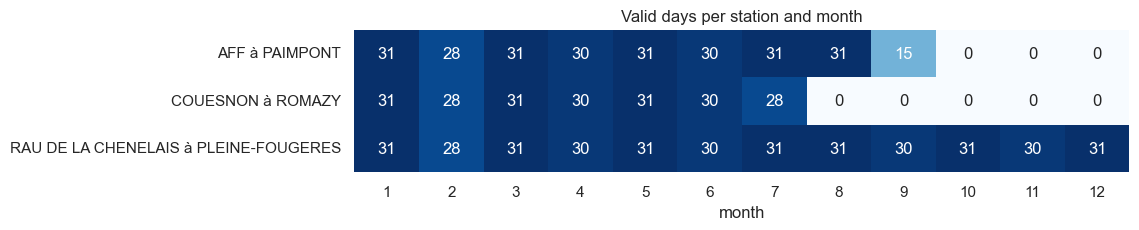

In [19]:
# Where in the year are the hours missing? Valid days per station and month.
hours_per_day = df.dropna(subset=["resultat"]).groupby(["libelle_station", df["ts"].dt.date]).size()
valid_days = hours_per_day[hours_per_day >= MIN_HOURS_PER_DAY].reset_index()
valid_days["month"] = pd.to_datetime(valid_days["ts"]).dt.month
coverage = valid_days.pivot_table(index="libelle_station", columns="month", values="ts",
                                  aggfunc="size", fill_value=0)
fig, ax = plt.subplots(figsize=(10, 0.5 + 0.45 * len(coverage)))
sns.heatmap(coverage, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set(xlabel="month", ylabel="", title="Valid days per station and month")
plt.show()

In [20]:
# Test: does missingness depend on the season (MAR) or is it spread evenly (MCAR)?
season = {12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
          6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"}
days_in_month = pd.Series(pd.date_range(start, end.normalize(), freq="D")).dt.month.value_counts().sort_index()
missing_by_season = ((1 - coverage / days_in_month).T
                     .assign(season=lambda t: t.index.map(season))
                     .groupby("season").mean().T.round(2))
missing_by_season[["winter", "spring", "summer", "autumn"]]

season,winter,spring,summer,autumn
libelle_station,,,,
AFF à PAIMPONT,0.33,0.0,0.00,0.83
COUESNON à ROMAZY,0.33,0.0,0.37,1.00
RAU DE LA CHENELAIS à PLEINE-FOUGERES,0.00,0.0,0.00,0.00


**Mechanism.** *TO COMPLETE after the full collection:*
- If one station is missing whole months and the others are not → **sensor removed or broken**: the gap depends on the station's history, not on temperature. Treat as MAR on station/time; do not interpolate across weeks.
- If gaps concentrate in **late summer** → suspicious: low water can leave the sensor dry (MNAR — the missing values would be the *hottest* ones), so summer means would be biased **downwards**.
- A station whose series stops exactly when the collection stops → **collection artefact**, not a sensor gap (see Section 3).

In [21]:
n_missing_hours = int((per_station["expected_hours"] - per_station["n_rows"]).sum())
log("ts", "missing hours (no row sent by the sensor)", n_missing_hours,
    "not imputed; daily means only from days with enough hours; covered months checked per station",
    "interpolating weeks of missing data would invent temperatures; see coverage heatmap and season test")

### 4.4 Spikes and outliers — triage, don't delete

In [22]:
# A global IQR fence is useless here: 4 °C is normal in January and impossible in August.
# So we compare each value with its own station's recent behaviour.
g = df.groupby("code_station")["resultat"]
df["jump_1h"] = g.diff().abs()
df["dev_7d"] = (df["resultat"] - g.transform(
    lambda s: s.rolling(24 * 7, center=True, min_periods=24).median())).abs()
df["spike"] = (df["jump_1h"] > SPIKE_JUMP_C) | (df["dev_7d"] > SPIKE_DEV_C)

print(f"largest 1-hour change: {df['jump_1h'].max():.2f} °C · largest gap to 7-day median: {df['dev_7d'].max():.2f} °C")
print(f"flagged as spikes (> {SPIKE_JUMP_C} °C in 1 h or > {SPIKE_DEV_C} °C from the 7-day median): {int(df['spike'].sum())}")
df.nlargest(8, "dev_7d")[["libelle_station", "ts", "resultat", "jump_1h", "dev_7d", "spike"]]

largest 1-hour change: 1.05 °C · largest gap to 7-day median: 3.88 °C
flagged as spikes (> 2.0 °C in 1 h or > 5.0 °C from the 7-day median): 0


,libelle_station,ts,resultat,jump_1h,dev_7d,spike
11977,RAU DE LA CHENELAIS à PLEINE-FOUGERES,2023-10-17 10:00:00,9.977,0.024000,3.881000,False
11976,RAU DE LA CHENELAIS à PLEINE-FOUGERES,2023-10-17 09:00:00,10.001,0.025000,3.857000,False
11975,RAU DE LA CHENELAIS à PLEINE-FOUGERES,2023-10-17 08:00:00,10.026,0.049000,3.832000,False
11978,RAU DE LA CHENELAIS à PLEINE-FOUGERES,2023-10-17 11:00:00,10.051,0.073999,3.807001,False
11974,RAU DE LA CHENELAIS à PLEINE-FOUGERES,2023-10-17 07:00:00,10.075,0.049000,3.783000,False
11973,RAU DE LA CHENELAIS à PLEINE-FOUGERES,2023-10-17 06:00:00,10.124,0.098001,3.734001,False
11979,RAU DE LA CHENELAIS à PLEINE-FOUGERES,2023-10-17 12:00:00,10.149,0.098001,3.709000,False
11972,RAU DE LA CHENELAIS à PLEINE-FOUGERES,2023-10-17 05:00:00,10.222,0.098000,3.636000,False


**Triage.** *TO COMPLETE after the full collection:* look at the flagged rows (and the largest deviations even if unflagged). A sensor out of the water shows **big jumps and a large day/night swing** (air temperature); a real event (storm, cold rain, heatwave) moves **gradually over several hours** and often shows at several stations the same days.

In [23]:
n_spike = int(df["spike"].sum())
df.loc[df["spike"], "resultat"] = np.nan
log("resultat", f"spikes: > {SPIKE_JUMP_C} °C in 1 h or > {SPIKE_DEV_C} °C from the station's 7-day median", n_spike,
    "set to NaN (kept in raw data)", "physically too fast for a river: typical of a sensor out of the water reading air")
log("resultat", "largest real deviations below the spike thresholds", int((df["dev_7d"] > 3).sum()),
    "kept", "gradual changes over hours: real weather events, exactly what the seasonal analysis must see")

### 4.5 One value per station and day, so stations can be compared

In [24]:
daily = (df.dropna(subset=["resultat"])
           .groupby(["code_station", "libelle_station", df["ts"].dt.normalize().rename("date")])
           .agg(temp_mean=("resultat", "mean"), temp_min=("resultat", "min"),
                temp_max=("resultat", "max"), n_hours=("resultat", "size"))
           .reset_index())
n_short_days = int((daily["n_hours"] < MIN_HOURS_PER_DAY).sum())
daily = daily[daily["n_hours"] >= MIN_HOURS_PER_DAY].reset_index(drop=True)
daily["month"] = daily["date"].dt.month
daily["season"] = daily["month"].map(season)
log("ts", "different sampling frequencies / incomplete days", n_short_days,
    f"resampled to one daily mean per station; days with < {MIN_HOURS_PER_DAY} hours dropped",
    "comparing raw rows would give more weight to stations that measure more often")
print(daily.shape)
daily.head()

(832, 9)


,code_station,libelle_station,date,temp_mean,temp_min,temp_max,n_hours,month,season
0,04162300,COUESNON à ROMAZY,2023-01-01,11.164250,11.053,11.248,24,1,winter
1,04162300,COUESNON à ROMAZY,2023-01-02,10.730042,10.394,11.029,24,1,winter
2,04162300,COUESNON à ROMAZY,2023-01-03,9.896708,9.706,10.320,24,1,winter
3,04162300,COUESNON à ROMAZY,2023-01-04,10.188375,9.854,10.590,24,1,winter
4,04162300,COUESNON à ROMAZY,2023-01-05,10.884708,10.638,11.078,24,1,winter


In [25]:
decision_table = pd.DataFrame(decisions, columns=["column", "issue", "n_rows", "decision", "why"])
decision_table.to_csv(REPORTS / "decision_table.csv", index=False)
decision_table

,column,issue,n_rows,decision,why
0,all,exact duplicate rows,0,dropped,identical on every column: the same measuremen...
1,ts,same station + timestamp twice (daylight-savin...,3,merged each pair into one row (mean of the two...,timestamps are local time: 02:00 does not exis...
2,code_unite,unit other than °C,0,dropped (none found),"checked, not assumed: mixing units would corru..."
3,resultat,"temperature outside [0.0, 30.0] °C",0,set to NaN (none found),below 0 °C river water would be ice; above 30 ...
4,code_qualification,measurements not validated by the producer ('N...,19997,"kept, flagged as a limitation in the report",every row is unvalidated raw sensor data: no p...
5,ts,missing hours (no row sent by the sensor),6283,not imputed; daily means only from days with e...,interpolating weeks of missing data would inve...
6,resultat,spikes: > 2.0 °C in 1 h or > 5.0 °C from the s...,0,set to NaN (kept in raw data),physically too fast for a river: typical of a ...
7,resultat,largest real deviations below the spike thresh...,36,kept,gradual changes over hours: real weather event...
8,ts,different sampling frequencies / incomplete days,2,resampled to one daily mean per station; days ...,comparing raw rows would give more weight to s...


---
## 5 · Exploration — every figure gets a caption and a *so what*

In [26]:
def show(fig, title, caption, so_what, name):
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    fig.text(0.01, -0.04, f"{caption}\n→ {so_what}", ha="left", va="top", fontsize=9, wrap=True)
    fig.savefig(REPORTS / f"{name}.png", bbox_inches="tight", dpi=120)
    plt.show()

clean = df.copy()      # TODO: this should be your cleaned data after Section 4

### 5.1 Univariate

In [27]:
# TODO: one figure showing the distribution of your key variable (ECDF before `.describe()`)
# fig, ax = plt.subplots(figsize=(8, 4))
# ...
# show(fig, "<title that states the finding>", "<what the figure shows>", "<what a modeller should do>", "5_1")

### 5.2 Bivariate

In [28]:
# TODO: one figure showing your key variable against 1–2 explanatory variables
# fig, ax = plt.subplots(figsize=(8, 4))
# ...
# show(fig, "<title that states the finding>", "<what the figure shows>", "<what a modeller should do>", "5_2")

### 5.3 Multivariate

In [29]:
# TODO: one figure showing the correlation structure, or a breakdown by two categories
# fig, ax = plt.subplots(figsize=(8, 4))
# ...
# show(fig, "<title that states the finding>", "<what the figure shows>", "<what a modeller should do>", "5_3")

---
## 6 · Findings, what cannot be trusted, next steps

*TODO*

**Three findings** — each with the figure it comes from and what it means for modelling.
1.
2.
3.

**What cannot be trusted** — column, subset, and why.
-
-

**Five testable hypotheses** — variable, direction, population, test.
- H1:
- H2:
- H3:
- H4:
- H5:

### Final contract & fingerprint
*TODO*: write `clean_schema` for the data a modeller receives (it may differ from the raw schema). Then **Restart & Run All twice**: the fingerprint must be identical.

In [30]:
clean_schema = None                  # TODO: pa.DataFrameSchema({...}, strict=True)
if clean_schema is not None:
    clean_schema.validate(clean, lazy=True)
    print("✅ clean data passes the contract")

clean.to_parquet(DATA / "processed" / "clean.parquet", index=False)
fingerprint = hashlib.sha256(
    pd.util.hash_pandas_object(clean.astype(str), index=False).values.tobytes()).hexdigest()[:12]
print("rows:", len(clean), "· fingerprint:", fingerprint)

rows: 19997 · fingerprint: d14660f0f0c7


> **Reproducibility note.** The fingerprint is stable between runs *thanks to the cache*: the API data changes over time, so a run without the cache (or after `CACHE_HOURS`) can give a different fingerprint. That is expected — record the collection date in Section 1 and in the README, and commit the raw Parquet if it is small enough.